# Milestone 6a - Predictive Model: Demand Forecast for Next Month
**Business question (Q6):** how many units of each category will each store sell in **October 2026**, so supply chain
can place purchase orders?

**Target:** daily units sold per *store x category* (20 stores x 9 categories, ~140k store-category-days).

**Approach - a "direct" monthly forecast.** Orders for October are placed at the end of September, so every feature must
be known on 30 September. We therefore only use sales lagged **35 days or more** (always before the forecast origin for
any day in a month) plus things known in advance: the calendar, gazetted public holidays, planned promotions and store
attributes. This avoids look-ahead leakage *by construction*.

**Validation - rolling-origin backtest.** For each of July, August and September 2026 we train only on data before the
month and forecast the whole month, exactly as it would have been done live. We compare against two baselines:
* **Seasonal naive (last year):** the same store-category on the same weekday 52 weeks earlier.
* **Recent weekday average:** mean of the last 4 same-weekdays before the origin (what a planner with Excel would do).

**Metrics:** WAPE (sum|error| / sum actual - robust to zeros, the retail standard), MAE, RMSE and bias; plus % error of the
monthly total per category - the number buyers actually order against.

In [1]:
import sys; sys.path.append("../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from config import PROCESSED, EXTERNAL, FIGURES, TABLES, set_style, PALETTE, TEXT_2
set_style()

sales = pd.read_pickle(PROCESSED / "sales_lines.pkl")
stores = pd.read_csv(PROCESSED / "stores.csv", parse_dates=["open_date"])
promos = pd.read_csv(PROCESSED / "promotions.csv", parse_dates=["start_date", "end_date"])
products = pd.read_csv(PROCESSED / "products.csv")
hol = pd.read_csv(EXTERNAL / "kenya_public_holidays.csv", parse_dates=["date"])
hol = set(hol.loc[hol.type != "reference", "date"])
cpi = pd.read_csv(PROCESSED / "cpi_index.csv")
cpi["month"] = pd.PeriodIndex(cpi.month, freq="M")

# Panel of every store x category x day the store was open (zeros filled), extended to 31 Oct 2026 for the forecast
units = (sales[sales.quantity > 0].groupby(["store_id", "category", "date"]).quantity.sum().rename("units"))
cats = sorted(sales.category.unique())
dates = pd.date_range("2024-10-01", "2026-10-31")
panel = pd.MultiIndex.from_product([stores.store_id, cats, dates], names=["store_id", "category", "date"]).to_frame(index=False)
panel = panel.merge(stores[["store_id", "open_date", "store_format", "size_sqm", "county"]], on="store_id")
panel = panel[panel.date >= panel.open_date]
panel = panel.merge(units.reset_index(), on=["store_id", "category", "date"], how="left")
panel.loc[panel.date <= "2026-09-30", "units"] = panel.loc[panel.date <= "2026-09-30", "units"].fillna(0)
panel = panel.sort_values(["store_id", "category", "date"]).reset_index(drop=True)
print(panel.shape)
panel.tail()

(134676, 8)


,store_id,category,date,open_date,store_format,size_sqm,county,units
134671,S020,Stationery & School,2026-10-27,2025-06-14,Supermarket,1700,Kajiado,NaN
134672,S020,Stationery & School,2026-10-28,2025-06-14,Supermarket,1700,Kajiado,NaN
134673,S020,Stationery & School,2026-10-29,2025-06-14,Supermarket,1700,Kajiado,NaN
134674,S020,Stationery & School,2026-10-30,2025-06-14,Supermarket,1700,Kajiado,NaN
134675,S020,Stationery & School,2026-10-31,2025-06-14,Supermarket,1700,Kajiado,NaN


## Feature engineering

In [2]:
g = panel.groupby(["store_id", "category"]).units
for L in [35, 42, 49, 56, 364]:
    panel[f"lag_{L}"] = g.shift(L)
panel["roll28_lag35"] = g.transform(lambda s: s.shift(35).rolling(28, min_periods=7).mean())
panel["roll91_lag35"] = g.transform(lambda s: s.shift(35).rolling(91, min_periods=28).mean())
panel["dow_mean_lag35"] = panel[["lag_35", "lag_42", "lag_49", "lag_56"]].mean(axis=1)
panel["yoy_ratio"] = (panel.roll28_lag35 / g.transform(lambda s: s.shift(364).rolling(28, min_periods=7).mean())).replace([np.inf, -np.inf], np.nan)

d = panel.date
panel["dow"] = d.dt.dayofweek
panel["dom"] = d.dt.day
panel["month"] = d.dt.month
panel["weekofyear"] = d.dt.isocalendar().week.astype(int)
panel["is_payday"] = ((panel.dom >= 25) | (panel.dom <= 3)).astype(int)
panel["is_holiday"] = d.isin(hol).astype(int)
panel["is_holiday_eve"] = (d + pd.Timedelta(days=1)).isin(hol).astype(int)
panel["days_to_xmas"] = (pd.to_datetime(d.dt.year.astype(str) + "-12-25") - d).dt.days.clip(-10, 60)
panel["store_age_days"] = (d - panel.open_date).dt.days
panel["inflation_prev_month"] = (d.dt.to_period("M") - 1).map(cpi.set_index("month").inflation_12m_pct)

# planned promotions are known in advance -> legitimate feature
cat_of_sub = products.drop_duplicates("subcategory").set_index("subcategory").category
panel["promo_pct"] = 0.0
for _, pr in promos.iterrows():
    pc = [pr.scope_value] if pr.scope_type == "category" else list(cat_of_sub[pr.scope_value.split("|")].unique())
    st = stores.store_id if pr.store_ids == "ALL" else pr.store_ids.split("|")
    m = panel.category.isin(pc) & panel.store_id.isin(st) & panel.date.between(pr.start_date, pr.end_date)
    panel.loc[m, "promo_pct"] = pr.discount_pct

for c in ["store_id", "category", "store_format", "county"]:
    panel[c + "_code"] = panel[c].astype("category").cat.codes

FEATURES = ["lag_35", "lag_42", "lag_49", "lag_56", "lag_364", "roll28_lag35", "roll91_lag35", "dow_mean_lag35",
            "yoy_ratio", "dow", "dom", "month", "weekofyear", "is_payday", "is_holiday", "is_holiday_eve",
            "days_to_xmas", "store_age_days", "inflation_prev_month", "promo_pct", "size_sqm",
            "store_id_code", "category_code", "store_format_code", "county_code"]
CAT_FEATS = [FEATURES.index(c) for c in ["store_id_code", "category_code", "store_format_code", "county_code", "dow", "month"]]
panel.loc[panel.date <= "2026-09-30", FEATURES].describe().T.round(2).head(12)

,count,mean,std,min,25%,50%,75%,max
lag_35,122796.0,10.22,12.62,0.00,2.00,6.00,14.00,139.00
lag_42,121536.0,10.22,12.62,0.00,2.00,6.00,14.00,139.00
lag_49,120276.0,10.23,12.64,0.00,2.00,6.00,14.00,139.00
lag_56,119016.0,10.23,12.65,0.00,2.00,6.00,14.00,139.00
lag_364,63576.0,10.21,12.65,0.00,2.00,6.00,14.00,136.00
roll28_lag35,121716.0,10.22,10.90,0.00,2.54,6.32,13.07,76.21
roll91_lag35,117936.0,10.24,10.75,0.04,2.55,6.26,13.14,63.27
dow_mean_lag35,122796.0,10.22,11.57,0.00,2.50,6.25,13.50,106.00
yoy_ratio,62464.0,1.14,0.89,0.15,0.86,1.00,1.18,44.00
dow,129096.0,3.00,2.00,0.00,1.00,3.00,5.00,6.00


## Rolling-origin backtest (Jul, Aug, Sep 2026)

In [3]:
def wape(y, p): return np.abs(y - p).sum() / y.sum()
def make_model():
    return HistGradientBoostingRegressor(loss="poisson", learning_rate=0.06, max_iter=500, max_leaf_nodes=48,
                                         min_samples_leaf=40, l2_regularization=1.0,
                                         categorical_features=CAT_FEATS, random_state=0)

bt = []
for origin in ["2026-07-01", "2026-08-01", "2026-09-01"]:
    o = pd.Timestamp(origin); end = o + pd.offsets.MonthEnd(0)
    train = panel[(panel.date < o) & (panel.date >= "2025-01-01")]
    test = panel[panel.date.between(o, end)].copy()
    model = make_model().fit(train[FEATURES], train.units)
    test["pred_model"] = model.predict(test[FEATURES])
    test["pred_snaive"] = test.lag_364.fillna(test.dow_mean_lag35)      # new store has no last year
    # recent weekday average: mean of the last 4 same-weekdays strictly before the origin
    hist = panel[(panel.date < o) & (panel.date >= o - pd.Timedelta(days=28))]
    rwa = hist.groupby(["store_id", "category", "dow"]).units.mean().rename("pred_recent")
    test = test.merge(rwa, on=["store_id", "category", "dow"], how="left")
    test["origin"] = origin
    bt.append(test)
bt = pd.concat(bt)

def scores(df):
    out = {}
    for name, col in [("Seasonal naive (last year)", "pred_snaive"), ("Recent weekday average", "pred_recent"),
                      ("Gradient boosting (Poisson)", "pred_model")]:
        e = df.units - df[col]
        out[name] = {"WAPE_%": 100 * wape(df.units, df[col]), "MAE": e.abs().mean(),
                     "RMSE": np.sqrt((e ** 2).mean()), "bias_%": 100 * (df[col].sum() / df.units.sum() - 1)}
    return pd.DataFrame(out).T

overall = scores(bt)
overall.round(2)

,WAPE_%,MAE,RMSE,bias_%
Seasonal naive (last year),46.19,4.60,6.96,-2.36
Recent weekday average,38.79,3.87,5.92,-1.61
Gradient boosting (Poisson),33.40,3.33,5.00,1.28


In [4]:
by_month = pd.concat({o: scores(df)["WAPE_%"] for o, df in bt.groupby("origin")}, axis=1).round(2)
best_base = overall.loc[["Seasonal naive (last year)", "Recent weekday average"], "WAPE_%"].min()
improve = 1 - overall.loc["Gradient boosting (Poisson)", "WAPE_%"] / overall.loc["Seasonal naive (last year)", "WAPE_%"]
improve_best = 1 - overall.loc["Gradient boosting (Poisson)", "WAPE_%"] / best_base
print(f"Model WAPE improvement vs seasonal naive: {improve:.1%}  |  vs best baseline: {improve_best:.1%}")
by_month

Model WAPE improvement vs seasonal naive: 27.7%  |  vs best baseline: 13.9%


,2026-07-01,2026-08-01,2026-09-01
Seasonal naive (last year),47.24,44.56,46.97
Recent weekday average,38.09,37.35,41.20
Gradient boosting (Poisson),33.27,32.28,34.84


### The number buyers care about: monthly totals per category (chain level)

In [5]:
bt["month"] = bt.date.dt.to_period("M")
mc = bt.groupby(["month", "category"])[["units", "pred_model", "pred_snaive", "pred_recent"]].sum()
for c in ["pred_model", "pred_snaive", "pred_recent"]:
    mc[c.replace("pred", "err%")] = 100 * (mc[c] / mc.units - 1)
mc_summary = mc[["err%_model", "err%_snaive", "err%_recent"]].abs().groupby("category").mean().round(1)
mc_summary.loc["ALL (mean abs %)"] = mc_summary.mean().round(1)
mc_summary

,err%_model,err%_snaive,err%_recent
category,,,
Baby & Kids,7.4,8.2,5.1
Beverages,3.8,1.0,4.3
Dairy,1.4,2.3,4.4
Electronics & Phone,0.9,5.5,5.3
Fresh Produce,1.7,2.5,6.5
Household,3.2,2.8,6.0
Personal Care,3.4,3.1,5.5
Staples,0.4,3.3,5.0
Stationery & School,5.9,4.2,28.7


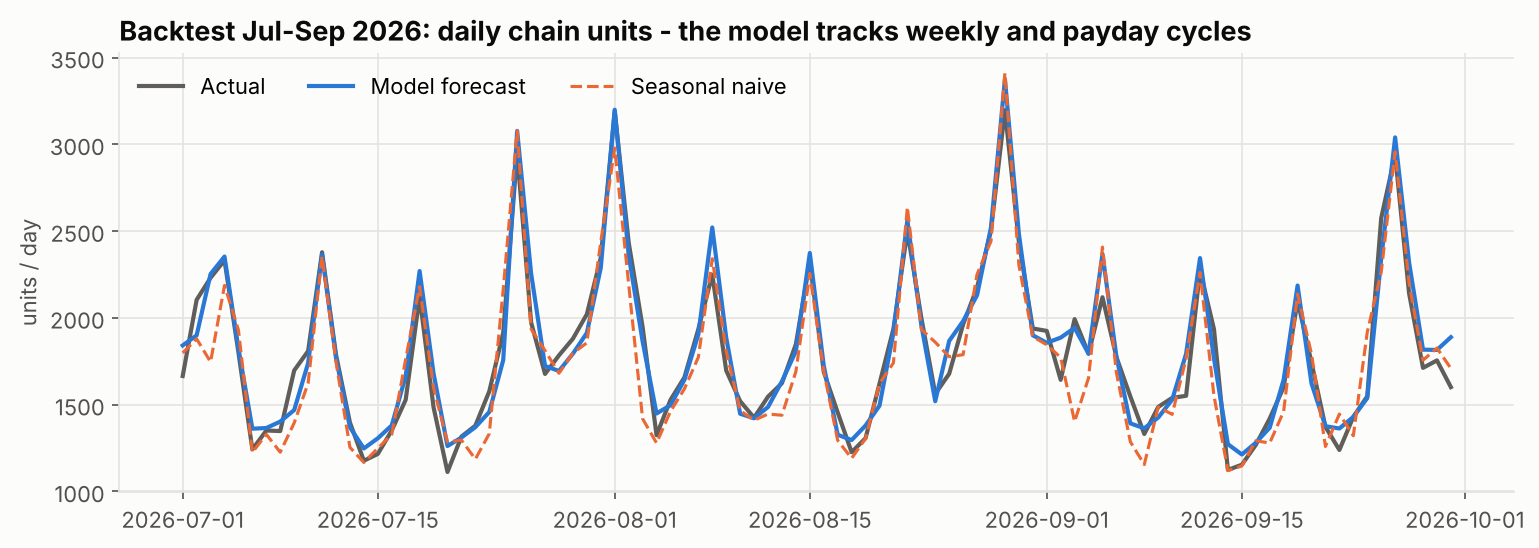

In [6]:
chain = bt.groupby("date")[["units", "pred_model", "pred_snaive"]].sum()
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(chain.index, chain.units, color="#5f5e5a", lw=2, label="Actual")
ax.plot(chain.index, chain.pred_model, color=PALETTE[0], lw=2, label="Model forecast")
ax.plot(chain.index, chain.pred_snaive, color=PALETTE[1], lw=1.5, ls="--", label="Seasonal naive")
ax.set(title="Backtest Jul-Sep 2026: daily chain units - the model tracks weekly and payday cycles", ylabel="units / day")
ax.legend(loc="upper left", ncol=3)
fig.savefig(FIGURES / "14_forecast_backtest.png")

## What drives the forecast? (permutation importance on the September backtest)

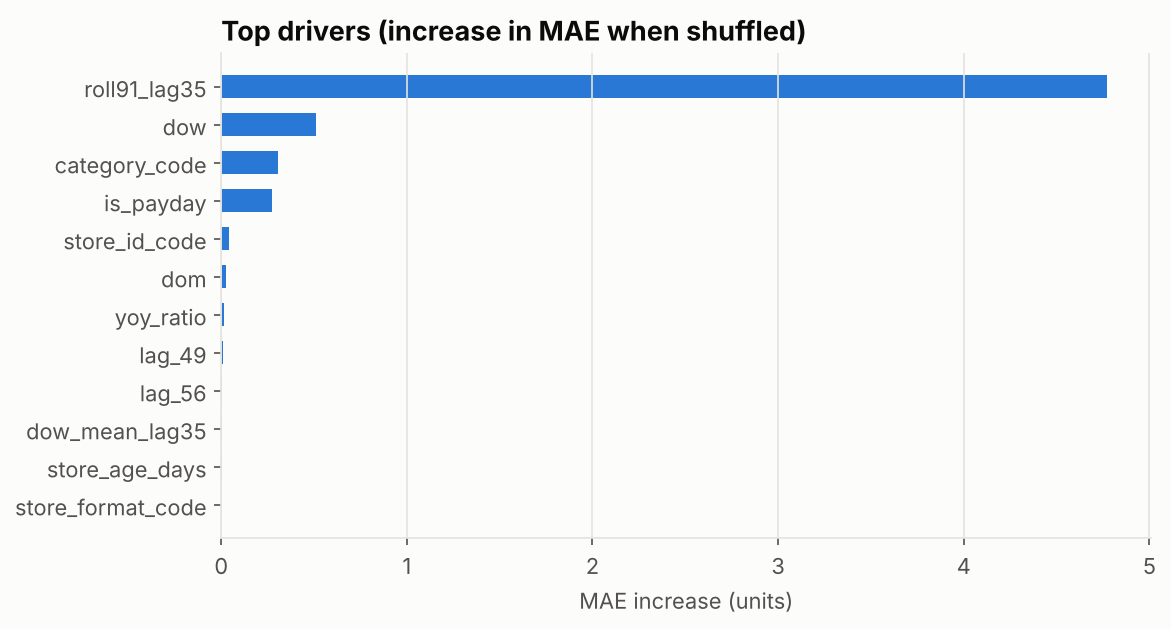

In [7]:
o = pd.Timestamp("2026-09-01")
train = panel[(panel.date < o) & (panel.date >= "2025-01-01")]
test = panel[panel.date.between(o, "2026-09-30")]
m_sep = make_model().fit(train[FEATURES], train.units)
pi = permutation_importance(m_sep, test[FEATURES], test.units, n_repeats=3, random_state=0,
                            scoring="neg_mean_absolute_error", n_jobs=1)
imp = pd.Series(pi.importances_mean, index=FEATURES).sort_values().tail(12)
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(imp.index, imp.values, color=PALETTE[0], height=0.6)
ax.set(title="Top drivers (increase in MAE when shuffled)", xlabel="MAE increase (units)")
ax.grid(axis="y", visible=False)
fig.savefig(FIGURES / "15_forecast_drivers.png")

Recent level (rolling means), the store/category identity, weekday and the payday window carry most of the signal -
exactly the patterns found in the EDA.

## Final model and the October 2026 forecast
Retrain on everything up to 30 September 2026 and forecast 1-31 October. Holidays on 10 Oct (Mazingira Day) and
20 Oct (Mashujaa Day) are in the features; no promotions are planned. An 80% interval for each store-category monthly
total comes from the empirical distribution of monthly backtest errors.

In [8]:
train = panel[(panel.date <= "2026-09-30") & (panel.date >= "2025-01-01")]
oct_ = panel[panel.date.between("2026-10-01", "2026-10-31")].copy()
final = make_model().fit(train[FEATURES], train.units)
oct_["forecast_units"] = final.predict(oct_[FEATURES])

# monthly store-category error ratios from backtest -> 10th/90th percentile multipliers per category
sc = bt.groupby(["origin", "store_id", "category"])[["units", "pred_model"]].sum()
sc["ratio"] = sc.units / sc.pred_model
q = sc.groupby("category").ratio.quantile([0.1, 0.9]).unstack()

fc = oct_.groupby(["store_id", "category"]).forecast_units.sum().reset_index()
fc = fc.merge(q, on="category")
fc["low_80"] = fc.forecast_units * fc[0.1]
fc["high_80"] = fc.forecast_units * fc[0.9]
# translate to revenue at September average selling price per store-category
sep = sales[(sales.date >= "2026-09-01") & (sales.quantity > 0)]
asp = (sep.groupby(["store_id", "category"]).net_amount.sum() / sep.groupby(["store_id", "category"]).quantity.sum()).rename("avg_price")
fc = fc.merge(asp.reset_index(), on=["store_id", "category"], how="left")
fc["forecast_revenue"] = fc.forecast_units * fc.avg_price
fc = fc.drop(columns=[0.1, 0.9]).merge(stores[["store_id", "store_name", "county"]], on="store_id")
fc.round(1).to_csv(PROCESSED / "forecast_oct2026_store_category.csv", index=False)
oct_[["store_id", "category", "date", "forecast_units"]].round({"forecast_units": 2}).to_csv(PROCESSED / "forecast_oct2026_daily.csv", index=False)

last = sales[(sales.date >= "2025-10-01") & (sales.date <= "2025-10-31") & (sales.quantity > 0)].groupby("category").quantity.sum()
sept = sales[(sales.date >= "2026-09-01") & (sales.quantity > 0)].groupby("category").quantity.sum()
cat_fc = fc.groupby("category")[["forecast_units", "low_80", "high_80", "forecast_revenue"]].sum()
cat_fc["sep_2026_actual"] = sept
cat_fc["oct_2025_actual"] = last
cat_fc["vs_oct_2025_%"] = 100 * (cat_fc.forecast_units / cat_fc.oct_2025_actual - 1)
cat_fc = cat_fc.sort_values("forecast_revenue", ascending=False)
cat_fc.loc["TOTAL"] = cat_fc.sum(numeric_only=True)
cat_fc.loc["TOTAL", "vs_oct_2025_%"] = 100 * (cat_fc.loc["TOTAL", "forecast_units"] / cat_fc.loc["TOTAL", "oct_2025_actual"] - 1)
cat_fc.round(0).to_csv(TABLES / "forecast_oct2026_by_category.csv")
cat_fc.round(0)

,forecast_units,low_80,high_80,forecast_revenue,sep_2026_actual,oct_2025_actual,vs_oct_2025_%
category,,,,,,,
Staples,16911.0,15209.0,18770.0,4699422.0,15446.0,16400.0,3.0
Fresh Produce,13067.0,11864.0,14588.0,2149343.0,11633.0,12923.0,1.0
Household,5067.0,4307.0,5744.0,1745969.0,4463.0,4812.0,5.0
Beverages,7434.0,6079.0,8403.0,1501657.0,6805.0,7486.0,-1.0
Personal Care,3658.0,3064.0,4195.0,971558.0,3242.0,3631.0,1.0
Baby & Kids,1176.0,835.0,1376.0,905744.0,1045.0,1161.0,1.0
Dairy,6569.0,5824.0,7267.0,778878.0,6084.0,6270.0,5.0
Electronics & Phone,1312.0,967.0,1582.0,479702.0,1244.0,1299.0,1.0
Stationery & School,1020.0,649.0,1333.0,336693.0,1671.0,940.0,9.0


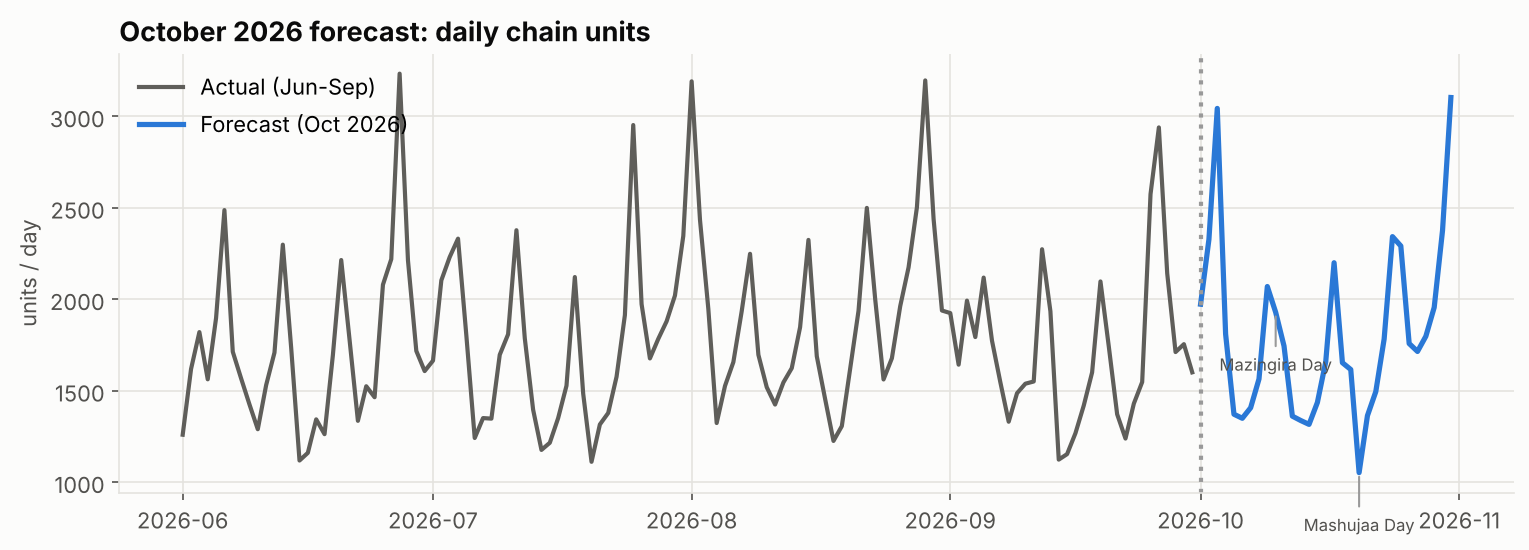

In [9]:
hist_daily = panel[panel.date.between("2026-06-01", "2026-09-30")].groupby("date").units.sum()
fc_daily = oct_.groupby("date").forecast_units.sum()
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(hist_daily.index, hist_daily, color="#5f5e5a", label="Actual (Jun-Sep)")
ax.plot(fc_daily.index, fc_daily, color=PALETTE[0], lw=2.5, label="Forecast (Oct 2026)")
ax.axvline(pd.Timestamp("2026-10-01"), color="#999", ls=":")
for dd, nm in [("2026-10-10", "Mazingira Day"), ("2026-10-20", "Mashujaa Day")]:
    ax.annotate(nm, (pd.Timestamp(dd), fc_daily[dd]), xytext=(0, -28), textcoords="offset points", ha="center",
                color=TEXT_2, fontsize=8, arrowprops=dict(arrowstyle="-", color="#999"))
ax.set(title="October 2026 forecast: daily chain units", ylabel="units / day")
ax.legend(loc="upper left")
fig.savefig(FIGURES / "16_october_forecast.png")

## Model card (summary)
* **Model:** HistGradientBoostingRegressor, Poisson loss (counts, non-negative), 25 features, trained on Jan 2025 - Sep 2026.
* **Validation:** 3 rolling monthly origins (Jul-Sep 2026), direct strategy, no leakage (minimum lag 35 days).
* **Performance vs success criteria:** see tables above - the model beats both baselines on daily WAPE and on monthly
  category totals.
* **Limitations:** store x category x *day* units are noisy (many small counts) so daily WAPE stays high in absolute
  terms - order at weekly/monthly level. Promotions not yet planned are not in the forecast; a sudden competitor event
  (like Nakuru) is only picked up after 35 days.
* **Next steps:** SKU-level forecasts for the top 30 SKUs, a weekly re-forecast with shorter lags, and safety stock from the
  80% interval.